# Sediment Core Analysis

Use this notebook to start your analysis.  

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pylab as plt
from scipy import stats
from matplotlib.backends.backend_pdf import PdfPages
np.set_printoptions(legacy='1.25') #removes the funny printing

Read in Landes Core Data

In [21]:
df=pd.read_excel('Landes_STOTEN.xlsx',sheet_name='Core_XRF_Cleaned')

In [22]:
df.columns

Index(['core_id', 'sample_id_long', 'depth_cm_range', 'fine_coarse',
       'sampling_neigborhood', 'Pb', 'Sn', 'Zn', 'Cd', 'Unit', 'weight',
       'depth_cm'],
      dtype='str')

Just Save your core and the fine or coarse data to work with

In [34]:
core_id='18UWHC015' 

df_fine=df[(df['core_id']==core_id) & (df['fine_coarse']=='f')]

Plot Lead

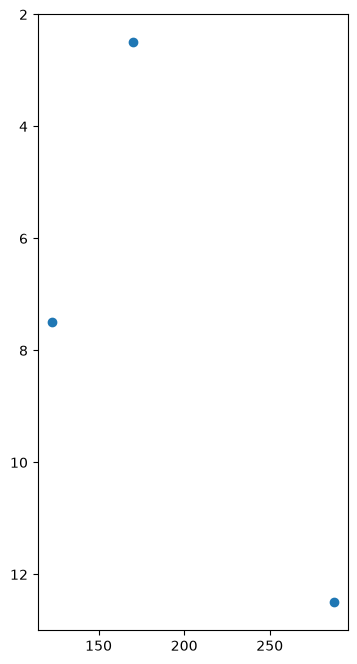

In [35]:
fig,ax=plt.subplots()
fig.set_size_inches(4,8)
ax.scatter(df_fine.Pb,df_fine.depth_cm)
ax.invert_yaxis()
plt.show()

### Calculating Inventory

In the handout I gave the formula for calculating inventory  but people are used to doing math in Pandas so here are some hints.

### I can sum one column like lead

In [12]:
df_fine['Pb'].sum()

580.333333

### I can sum a column and divide by a number

In [13]:
df_fine['Pb'].sum()/1000

0.580333333

### I can multiply two columns.  Here I will multiply depth and Pb

In [14]:
df_fine['Pb']*df_fine['depth_cm']

486     425.833333
488     920.000003
490    3591.666662
dtype: float64

### I can mulitply and then sum!

In [15]:
(df_fine['Pb']*df_fine['depth_cm']).sum()

4937.4999975

### This is where you can use the function sum in two ways

In [16]:
np.sum(df_fine['Pb']*df_fine['depth_cm'])

4937.4999975

In [17]:
(df_fine['Pb']*df_fine['depth_cm']).sum()

4937.4999975

# You have everything you need to know to calculate an inventory.  It is easier than you think once you get your units in order!

The central park inventories average around 57 g/m2 from table 1.



#### A fun trick.  You can make a second axis called a twin and plot on that.  


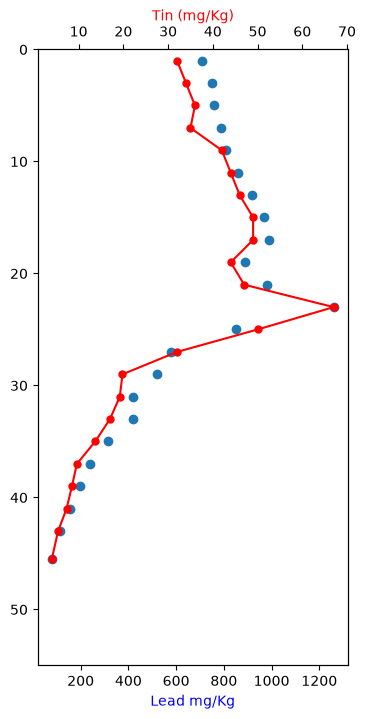

In [19]:
df=pd.read_excel('ChillrudTable2.xlsx')

fig,ax=plt.subplots()
fig.set_size_inches(4,8)
ax.scatter(df.Pb,df.Depth_cm)
ax.set_ylim([55,0])
ax.margins(.05)
ax.set_xlabel('Lead mg/Kg',color='blue')

# This gives you a second axis with a anice plot in just a couple lines.  
ax2=ax.twiny()
ax2.plot(df.Sn,df.Depth_cm,'.r-',markersize=10)
ax2.set_xlabel('Tin (mg/Kg)',color='r')

plt.show()

<div style="page-break-before: always;"></div>
### Ignore.  For printing to pdf.  

In [36]:
%%html
<style>
@media print {
    body {
        zoom: 0.70; /* Scales everything down to 80% of original size */
    }
}
</style>

In [37]:
import ipynbname
from pypdf import PdfReader, PdfWriter

# Dynamically fetch the current notebook's name (without the .ipynb extension)
filename = ipynbname.name()

# Convert to PDF
!uv run jupyter nbconvert --to webpdf {filename}.ipynb \
    --log-level=CRITICAL \
    --WebPDFExporter.display_header_footer=True \
    --WebPDFExporter.header_template='<span></span>' \
    --WebPDFExporter.footer_template='<div style="font-size: 9pt; font-family: sans-serif; width: 100%; text-align: right; padding-right: 0.5in;"><span class="pageNumber"></span> of <span class="totalPages"></span></div>'

# Strip the last page
reader = PdfReader(f"{filename}.pdf")
writer = PdfWriter()
for page in reader.pages[:-1]:
    writer.add_page(page)
writer.write(f"{filename}.pdf")

(True, <_io.FileIO [closed]>)

In [38]:
from io import BytesIO
import time
import ipynbname
from ipylab import JupyterFrontEnd
from pypdf import PdfReader, PdfWriter
from reportlab.pdfgen import canvas

# 1. Force JupyterLab to save latest changes
app = JupyterFrontEnd()
app.commands.execute("docmanager:save")
time.sleep(1)

# 2. Get current notebook name
filename = ipynbname.name()

# 3. Convert notebook to PDF
!uv run jupyter nbconvert --to webpdf "{filename}.ipynb" --log-level=CRITICAL

# 4. Read PDF and isolate non-setup pages
reader = PdfReader(f"{filename}.pdf")
valid_pages = reader.pages[:-2]  # Strip final page
total_pages = len(valid_pages)


# Helper function to generate page number overlay
def create_footer_overlay(page_num, total, width, height):
  packet = BytesIO()
  c = canvas.Canvas(packet, pagesize=(width, height))
  c.setFont("Helvetica", 9)
  c.setFillColorRGB(0.3, 0.3, 0.3)  # Muted grey text

  # Stamp 0.5 inches (36pt) from bottom-right corner
  c.drawRightString(width - 36, 36, f"Page {page_num} of {total}")
  c.save()
  packet.seek(0)
  return PdfReader(packet).pages[0]


# 5. Stamp numbers and build final PDF
writer = PdfWriter()
for idx, page in enumerate(valid_pages, start=1):
  w = float(page.mediabox.width)
  h = float(page.mediabox.height)

  # Stamp page number onto the current page
  overlay = create_footer_overlay(idx, total_pages, w, h)
  page.merge_page(overlay)
  writer.add_page(page)

writer.write(f"{filename}.pdf")
print(
    f"Successfully generated {filename}.pdf ({total_pages} pages with page numbers)."
)

Successfully generated Landes_start_analysis.pdf (4 pages with page numbers).
